# WikiBio Golden Layer Analysis

This notebook analyzes layer performance for WikiBio dataset with proper metric handling:
- **Rewrite Accuracy**: Edit success rate
- **Locality**: Relation specificity (average)
- **Fluency**: ngram_entropy (NEGATED - lower is better)
- **Overall**: Normalized average of all three metrics

In [1]:
import json
import numpy as np
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict
import pandas as pd
from golden_layer_api_wikirecent import GoldenLayerAnalyzerWikiRecent

plt.style.use('seaborn-v0_8-darkgrid')

## 1. Load WikiBio Data

WikiBio has a nested JSON structure that needs special handling.

In [2]:
def load_wikibio_data(data_dir='../allLayerPerformance', n_layers=48):
    """
    Load WikiRecent results from nested JSON files.
    
    Structure:
    {
      "post": {
        "rewrite_acc": [score],
        "locality": {"Relation_Specificity_acc": [scores...]},
        "fluency": {"ngram_entropy": value}
      }
    }
    """
    data_dir = Path(data_dir)
    
    # Storage for all layer data
    all_data = defaultdict(list)  # layer -> list of samples
    
    # Load all JSON files
    for layer in range(n_layers):
        layer_samples = []
        
        # Find all files for this layer
        for json_file in sorted(data_dir.glob(f"*_layer{layer}.json")):
            with open(json_file, 'r') as f:
                samples = json.load(f)
                
            for sample in samples:
                if 'post' not in sample:
                    continue
                    
                post = sample['post']
                
                # Extract metrics
                sample_data = {}
                
                # Rewrite accuracy
                if 'rewrite_acc' in post and isinstance(post['rewrite_acc'], list):
                    sample_data['rewrite_acc'] = post['rewrite_acc'][0]
                else:
                    sample_data['rewrite_acc'] = np.nan
                
                # Locality (Relation Specificity) - average the scores
                if ('locality' in post and 
                    'Relation_Specificity_acc' in post['locality']):
                    locality_scores = post['locality']['Relation_Specificity_acc']
                    if isinstance(locality_scores, list) and len(locality_scores) > 0:
                        sample_data['locality_acc'] = np.mean(locality_scores)
                    else:
                        sample_data['locality_acc'] = np.nan
                else:
                    sample_data['locality_acc'] = np.nan
                
                # Fluency (ngram_entropy)
                if ('fluency' in post and 
                    'ngram_entropy' in post['fluency']):
                    sample_data['fluency'] = post['fluency']['ngram_entropy']
                else:
                    sample_data['fluency'] = np.nan
                
                layer_samples.append(sample_data)
        
        all_data[layer] = layer_samples
    
    # Determine number of samples (max across all layers)
    n_samples = max(len(samples) for samples in all_data.values())
    
    # Convert to tensors (samples x layers)
    results = {}
    metrics = ['rewrite_acc', 'locality_acc', 'fluency']
    
    for metric in metrics:
        # Initialize tensor
        tensor = torch.full((n_samples, n_layers), float('nan'))
        
        # Fill with data
        for layer in range(n_layers):
            layer_samples = all_data[layer]
            for sample_idx, sample in enumerate(layer_samples):
                if sample_idx < n_samples:
                    tensor[sample_idx, layer] = sample.get(metric, np.nan)
        
        results[metric] = tensor
    
    print(f"\nLoaded WikiRecent data:")
    print(f"  Samples: {n_samples}")
    print(f"  Layers: {n_layers}")
    for metric, tensor in results.items():
        non_nan = (~torch.isnan(tensor)).sum().item()
        total = tensor.numel()
        print(f"  {metric}: {non_nan}/{total} non-NaN values")
    
    return results, n_samples, n_layers

# Load data
# results, n_samples, n_layers = load_wikibio_data()
analyzer = GoldenLayerAnalyzerWikiRecent()
analyzer.load_data()

Loaded WikiRecent data:
  Samples: 306
  Layers: 32
  Rewrite Accuracy: 9792/9792 non-NaN values
  Locality: 9792/9792 non-NaN values
  Portability: 0/9792 non-NaN values
  Fluency: 9792/9792 non-NaN values


## 2. Compute Overall Metric

**IMPORTANT**: Fluency (ngram_entropy) - lower is better, so we negate it before normalization.

In [3]:
def compute_overall_with_fluency_negation(results):
    """
    Compute overall metric:
    1. NEGATE fluency (lower is better → higher is better)
    2. Min-max normalize all metrics to [0, 1]
    3. Average the normalized metrics
    """
    # Step 1: Negate fluency
    fluency_negated = -results['fluency']
    
    # Step 2: Min-max normalize each metric
    normalized = {}
    
    for metric_name, values in [
        ('rewrite_acc', results['rewrite_acc']),
        ('locality_acc', results['locality_acc']),
        ('fluency_negated', fluency_negated)
    ]:
        valid_mask = ~torch.isnan(values)
        
        if valid_mask.sum() == 0:
            normalized[metric_name] = values
            print(f"{metric_name}: No valid data for normalization")
            continue
        
        min_val = values[valid_mask].min()
        max_val = values[valid_mask].max()
        
        if max_val - min_val > 1e-10:
            norm_values = (values - min_val) / (max_val - min_val)
        else:
            norm_values = torch.ones_like(values) * 0.5
        
        normalized[metric_name] = norm_values
        print(f"Normalized {metric_name}: [{min_val:.4f}, {max_val:.4f}] → [0, 1]")
    
    # Step 3: Compute overall as average
    overall = (
        normalized['rewrite_acc'] +
        normalized['locality_acc'] +
        normalized['fluency_negated']
    ) / 3.0
    
    results['overall'] = overall
    
    non_nan = (~torch.isnan(overall)).sum().item()
    total = overall.numel()
    print(f"\nComputed overall: {non_nan}/{total} non-NaN values")
    
    return results

# Compute overall metric
# results = compute_overall_with_fluency_negation(results)
analyzer.compute_overall_metric()

Min-max normalized rewrite_acc per-sample across layers
Min-max normalized locality_acc per-sample across layers
Min-max normalized portability_acc per-sample across layers
Min-max normalized fluency_negated per-sample across layers

Computed post_overall metric: 9792 / 9792 non-NaN values


/home/user/Projects/EasyEditEdited/sampleLayerRelationshipWikiBioGemma31/golden_layer/golden_layer_api_wikirecent.py:182: RuntimeWarning: All-NaN slice encountered
  min_vals = np.nanmin(tensor, axis=1, keepdims=True)
/home/user/Projects/EasyEditEdited/sampleLayerRelationshipWikiBioGemma31/golden_layer/golden_layer_api_wikirecent.py:183: RuntimeWarning: All-NaN slice encountered
  max_vals = np.nanmax(tensor, axis=1, keepdims=True)


## 3. Split into Proxy and Test Sets

In [4]:
def split_dataset(results, n_samples, proxy_size=80, random_seed=42):
    """Split into proxy and test sets"""
    torch.manual_seed(random_seed)
    indices = torch.randperm(n_samples)
    
    proxy_indices = indices[:proxy_size]
    test_indices = indices[proxy_size:]
    
    # Compute means for each set
    proxy_means = {}
    test_means = {}
    
    for metric, values in results.items():
        proxy_means[metric] = values[proxy_indices].nanmean(dim=0)
        test_means[metric] = values[test_indices].nanmean(dim=0)
    
    print(f"\nDataset split:")
    print(f"  Proxy set: {len(proxy_indices)} samples")
    print(f"  Test set: {len(test_indices)} samples")
    
    return proxy_means, test_means, proxy_indices, test_indices

# proxy_means, test_means, proxy_indices, test_indices = split_dataset(
#     results, n_samples, proxy_size=120
# )

analyzer.split_dataset(proxy_size=80)


Dataset split:
  Total samples: 306
  Proxy set: 80 samples
  Test set: 226 samples


## 3a. Specific Layer Performance Analysis

Analyze performance at a specific layer of interest across different sample ranges.

In [5]:
# Analyze a specific layer (e.g., layer 17)
layer_idx = 17

print(f"{'='*70}")
print(f"LAYER {layer_idx} PERFORMANCE ANALYSIS")
print(f"{'='*70}")

# Define metrics info
metrics_info = analyzer.metrics_info

# Analyze different sample ranges if dataset is large enough
if analyzer.n_samples >= 300:
    print(f"\nFirst 300 samples (indices 0-299):")
    for metric_key, metric_name in metrics_info:
        layer_values = analyzer.results[metric_key][:300, layer_idx]
        valid_values = layer_values[~torch.isnan(layer_values)]
        if len(valid_values) > 0:
            mean_val = valid_values.mean().item()
            print(f"  {metric_name:20s}: {mean_val:.4f} (n={len(valid_values)})")
        else:
            print(f"  {metric_name:20s}: No valid data")

print(f"\nAll {analyzer.n_samples} samples:")
for metric_key, metric_name in metrics_info:
    layer_values = analyzer.results[metric_key][:, layer_idx]
    valid_values = layer_values[~torch.isnan(layer_values)]
    if len(valid_values) > 0:
        mean_val = valid_values.mean().item()
        print(f"  {metric_name:20s}: {mean_val:.4f} (n={len(valid_values)})")
    else:
        print(f"  {metric_name:20s}: No valid data")

LAYER 17 PERFORMANCE ANALYSIS

First 300 samples (indices 0-299):
  Rewrite Accuracy    : 0.7611 (n=300)
  Locality            : 0.7153 (n=300)
  Portability         : No valid data
  Fluency             : 4.9044 (n=300)
  Overall             : 0.5049 (n=300)

All 306 samples:
  Rewrite Accuracy    : 0.7603 (n=306)
  Locality            : 0.7134 (n=306)
  Portability         : No valid data
  Fluency             : 4.9146 (n=306)
  Overall             : 0.5042 (n=306)


## 4. Find Best Layers and Correlations

In [6]:
def analyze_best_layers(proxy_means, test_means):
    """Find best layers and compute correlations"""
    
    analysis = {}
    
    # ALL metrics including fluency
    metrics_info = [
        ('rewrite_acc', 'Rewrite Accuracy'),
        ('locality_acc', 'Locality'),
        ('portability_acc', 'Portability'),
        ('fluency', 'Fluency (raw - lower is better)'),
        ('overall', 'Overall')
    ]
    
    print("\nBest Layer Analysis:")
    print("="*70)
    
    for metric_key, metric_name in metrics_info:
        if metric_key not in proxy_means or metric_key not in test_means:
            continue
            
        proxy_mean = proxy_means[metric_key]
        test_mean = test_means[metric_key]
        
        # Find best layers (handle NaN values properly)
        # For fluency (raw), LOWER is better, so find MIN instead of MAX
        valid_proxy = ~torch.isnan(proxy_mean)
        valid_test = ~torch.isnan(test_mean)
        
        if metric_key == 'fluency':
            # For fluency: lower is better
            if valid_proxy.sum() > 0:
                proxy_best_val = proxy_mean[valid_proxy].min()  # MIN for fluency
                proxy_best = torch.where(proxy_mean == proxy_best_val)[0].tolist()
            else:
                proxy_best_val = torch.tensor(float('nan'))
                proxy_best = []
            
            if valid_test.sum() > 0:
                test_best_val = test_mean[valid_test].min()  # MIN for fluency
                test_best = torch.where(test_mean == test_best_val)[0].tolist()
            else:
                test_best_val = torch.tensor(float('nan'))
                test_best = []
        else:
            # For other metrics: higher is better
            if valid_proxy.sum() > 0:
                proxy_best_val = proxy_mean[valid_proxy].max()
                proxy_best = torch.where(proxy_mean == proxy_best_val)[0].tolist()
            else:
                proxy_best_val = torch.tensor(float('nan'))
                proxy_best = []
            
            if valid_test.sum() > 0:
                test_best_val = test_mean[valid_test].max()
                test_best = torch.where(test_mean == test_best_val)[0].tolist()
            else:
                test_best_val = torch.tensor(float('nan'))
                test_best = []
        
        overlap = list(set(proxy_best) & set(test_best))
        
        # Compute correlation
        valid_mask = ~(torch.isnan(proxy_mean) | torch.isnan(test_mean))
        if valid_mask.sum() > 1:
            corr = torch.corrcoef(torch.stack([
                proxy_mean[valid_mask],
                test_mean[valid_mask]
            ]))[0, 1].item()
        else:
            corr = np.nan
        
        analysis[metric_key] = {
            'name': metric_name,
            'proxy_best': proxy_best,
            'proxy_score': proxy_best_val.item(),
            'test_best': test_best,
            'test_score': test_best_val.item(),
            'overlap': overlap,
            'correlation': corr
        }
        
        indicator = "(lower is better)" if metric_key == 'fluency' else ""
        print(f"\n{metric_name} {indicator}:")
        print(f"  Proxy: Layers {proxy_best} (score: {proxy_best_val:.4f})")
        print(f"  Test:  Layers {test_best} (score: {test_best_val:.4f})")
        print(f"  Overlap: {overlap if overlap else 'None'}")
        print(f"  Correlation: r = {corr:.4f}")
    
    return analysis

# analysis = analyze_best_layers(proxy_means, test_means)
analyzer.compute_proxy_test_means()
analyzer.analyze()


Computed proxy and test means for all metrics

Rewrite Accuracy:
  Proxy best: [13] (score: 0.8589)
  Test best: [13] (score: 0.8508)
  Overlap: [13]
  Correlation: r = 0.9727

Locality:
  Proxy best: [0] (score: 0.8293)
  Test best: [15] (score: 0.8404)
  Overlap: None
  Correlation: r = 0.9022

Portability:
  Proxy best: [] (score: nan)
  Test best: [] (score: nan)
  Overlap: None
  Correlation: r = nan

Fluency:
  Proxy best: [15] (score: 4.9157)
  Test best: [7] (score: 4.8818)
  Overlap: None
  Correlation: r = 0.8450

Overall:
  Proxy best: [13] (score: 0.6339)
  Test best: [11] (score: 0.6401)
  Overlap: None
  Correlation: r = 0.9667


## 4a. Average Performance Statistics: Proxy vs Test

Compare average performance across all layers between proxy and test sets.

In [7]:
# Display average performance statistics
print(f"\n{'='*70}")
print("AVERAGE PERFORMANCE: PROXY vs TEST")
print(f"{'='*70}")

for metric_key, metric_name in metrics_info:
    if metric_key in analyzer.proxy_means and metric_key in analyzer.test_means:
        proxy_avg = analyzer.proxy_means[metric_key].nanmean().item()
        test_avg = analyzer.test_means[metric_key].nanmean().item()
        
        print(f"\n{metric_name}:")
        print(f"  Proxy set (avg across all layers): {proxy_avg:.4f}")
        print(f"  Test set (avg across all layers):  {test_avg:.4f}")
        print(f"  Difference: {abs(proxy_avg - test_avg):.4f}")


AVERAGE PERFORMANCE: PROXY vs TEST

Rewrite Accuracy:
  Proxy set (avg across all layers): 0.7393
  Test set (avg across all layers):  0.7588
  Difference: 0.0195

Locality:
  Proxy set (avg across all layers): 0.7537
  Test set (avg across all layers):  0.7461
  Difference: 0.0076

Portability:
  Proxy set (avg across all layers): nan
  Test set (avg across all layers):  nan
  Difference: nan

Fluency:
  Proxy set (avg across all layers): 4.9654
  Test set (avg across all layers):  4.9463
  Difference: 0.0191

Overall:
  Proxy set (avg across all layers): 0.4998
  Test set (avg across all layers):  0.5167
  Difference: 0.0170


## 5. Golden Layer Summary

In [8]:
print("\n" + "="*70)
print("GOLDEN LAYER IDENTIFICATION")
print("="*70)
analysis = analyzer.best_layers_comparison

overall_info = analysis['overall']

print(f"\nProxy best layers:  {overall_info['proxy_best_layers']} (score: {overall_info['proxy_score']:.4f})")
print(f"Test best layers:   {overall_info['test_best_layers']} (score: {overall_info['test_score']:.4f})")

if overall_info['overlap']:
    print(f"\n✓✓✓ GOLDEN LAYER(S) FOUND: {overall_info['overlap']} ✓✓✓")
    print("These layers perform best on both proxy and test sets!")
else:
    print("\n✗ No perfect overlap between proxy and test best layers")
    print("Consider using proxy layers or analyzing correlation.")

# Correlation summary
correlations = [info['correlation'] for info in analysis.values() 
                if not np.isnan(info['correlation'])]

print(f"\nCORRELATION SUMMARY:")
print(f"  Average: {np.mean(correlations):.4f}")
print(f"  Min: {np.min(correlations):.4f}")
print(f"  Max: {np.max(correlations):.4f}")


GOLDEN LAYER IDENTIFICATION

Proxy best layers:  [13] (score: 0.6339)
Test best layers:   [11] (score: 0.6401)

✗ No perfect overlap between proxy and test best layers
Consider using proxy layers or analyzing correlation.

CORRELATION SUMMARY:
  Average: 0.9216
  Min: 0.8450
  Max: 0.9727


## 6. Visualizations

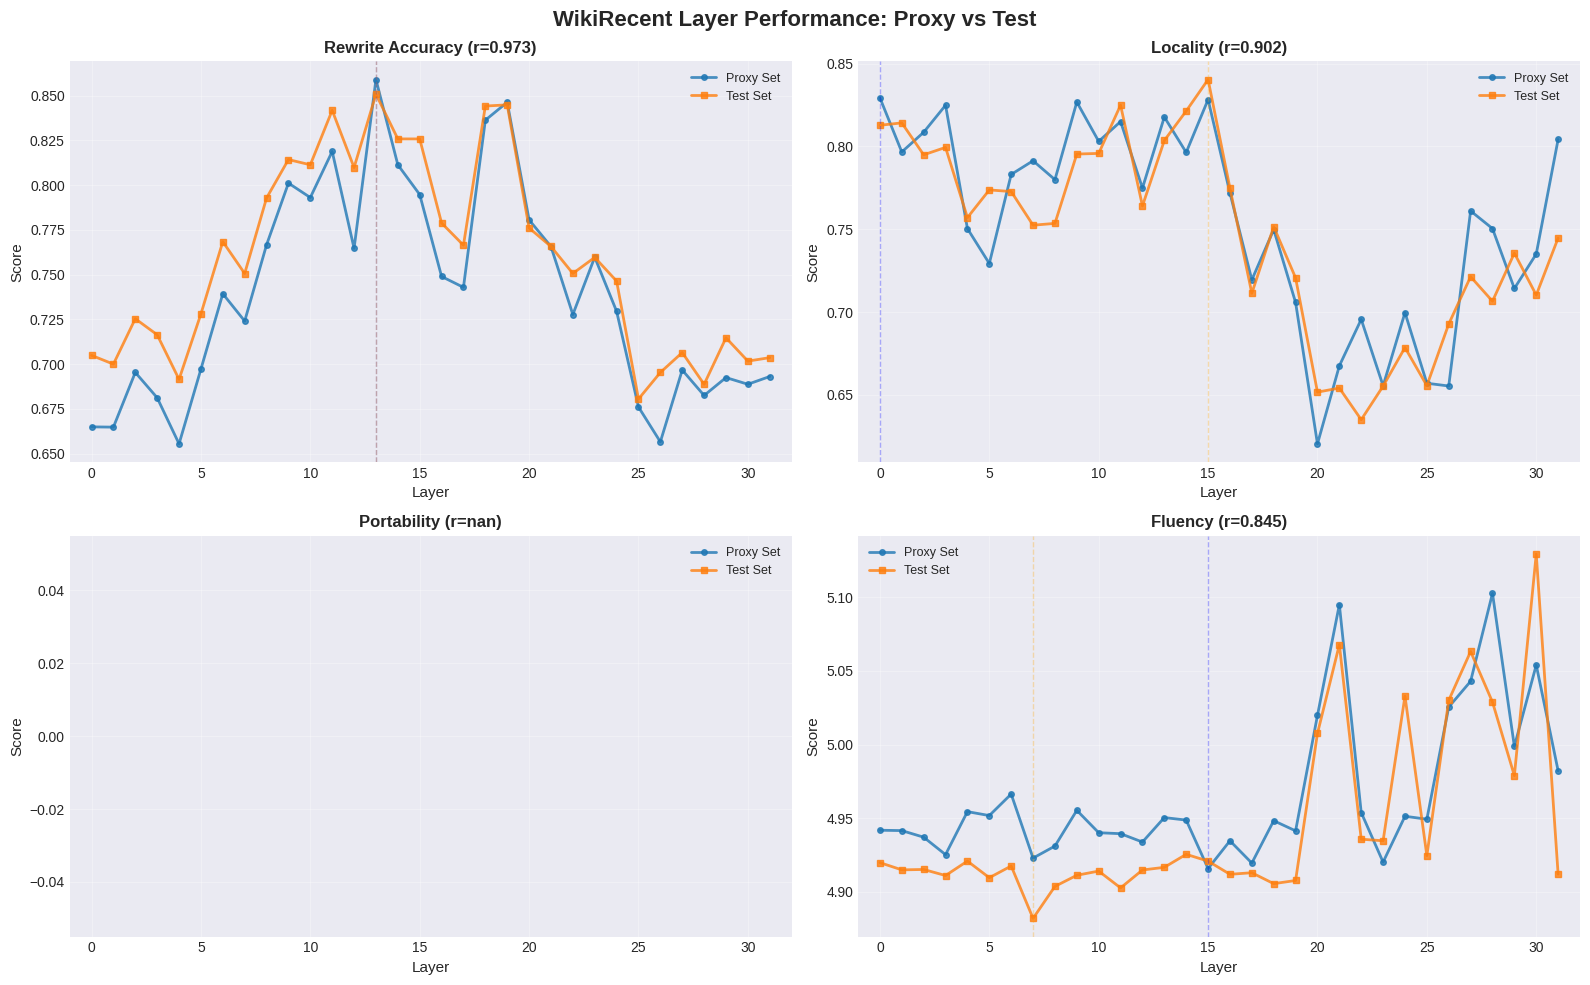

In [9]:
# Plot layer performance curves - ALL 4 metrics
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('WikiRecent Layer Performance: Proxy vs Test', fontsize=16, fontweight='bold')
axes = axes.flatten()

layers_array = np.arange(analyzer.n_layers)

for idx, (metric_key, info) in enumerate(analysis.items()):
    if idx >= 4:
        break
    
    ax = axes[idx]
    metric_name = info['name']
    
    proxy_values = analyzer.proxy_means[metric_key].numpy()
    test_values = analyzer.test_means[metric_key].numpy()
    
    # Plot curves
    ax.plot(layers_array, proxy_values, marker='o', linewidth=2, markersize=4,
            label='Proxy Set', alpha=0.8)
    ax.plot(layers_array, test_values, marker='s', linewidth=2, markersize=4,
            label='Test Set', alpha=0.8)
    
    # Mark best layers
    for layer in info['proxy_best_layers']:
        ax.axvline(layer, color='blue', linestyle='--', alpha=0.3, linewidth=1)
    for layer in info['test_best_layers']:
        ax.axvline(layer, color='orange', linestyle='--', alpha=0.3, linewidth=1)
    
    ax.set_xlabel('Layer', fontsize=11)
    ax.set_ylabel('Score', fontsize=11)
    ax.set_title(f"{metric_name} (r={info['correlation']:.3f})", 
                fontsize=12, fontweight='bold')
    ax.legend(loc='best', fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(-1, analyzer.n_layers)

plt.tight_layout()
plt.show()

## 7. Bar Chart Comparison

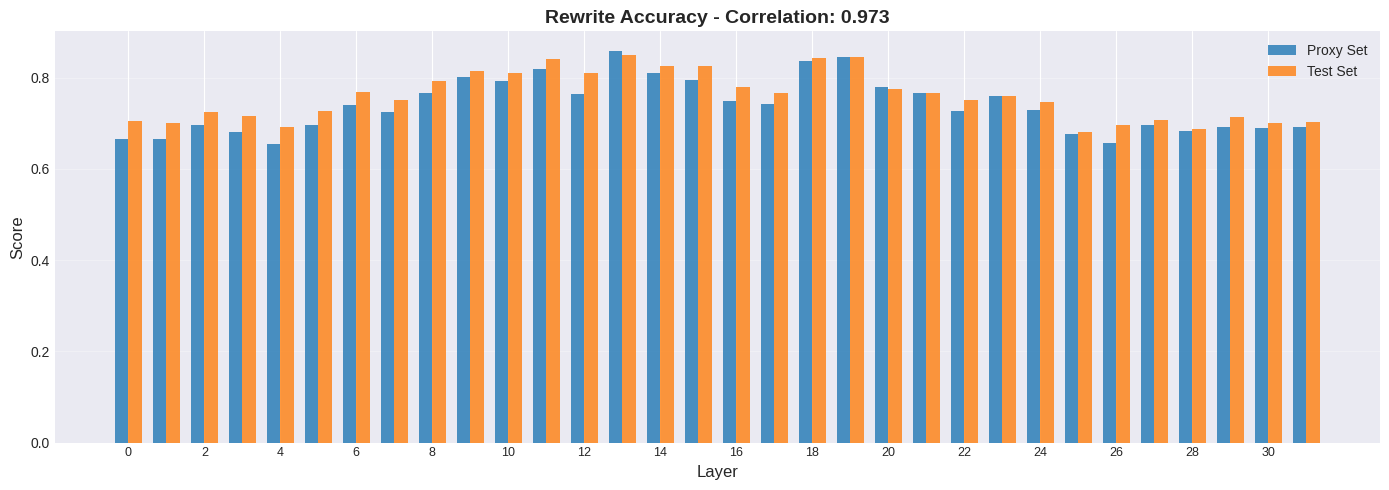

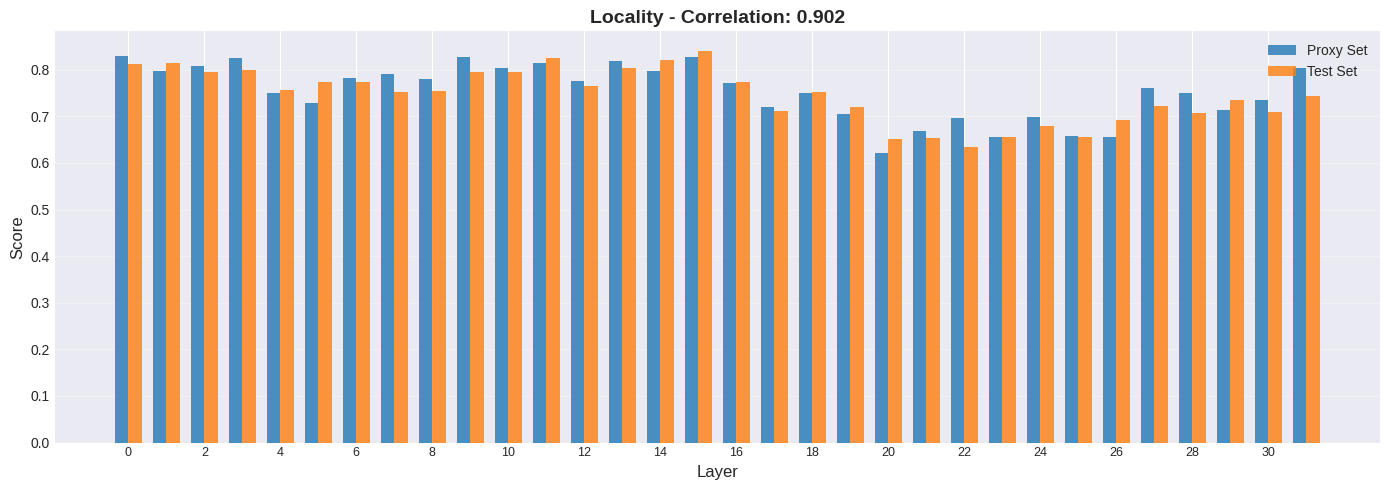

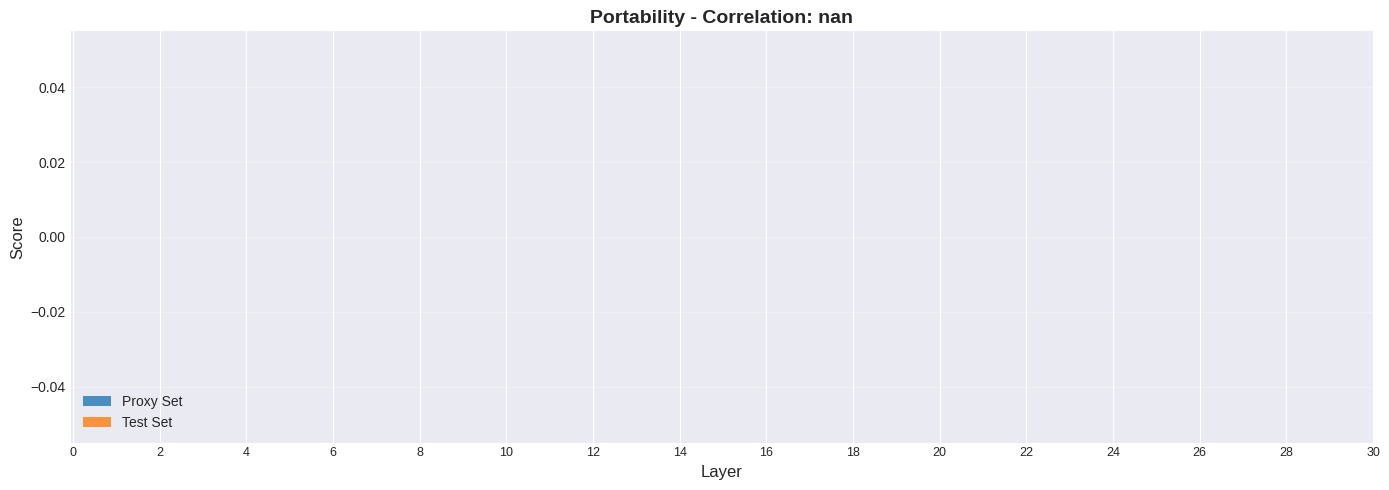

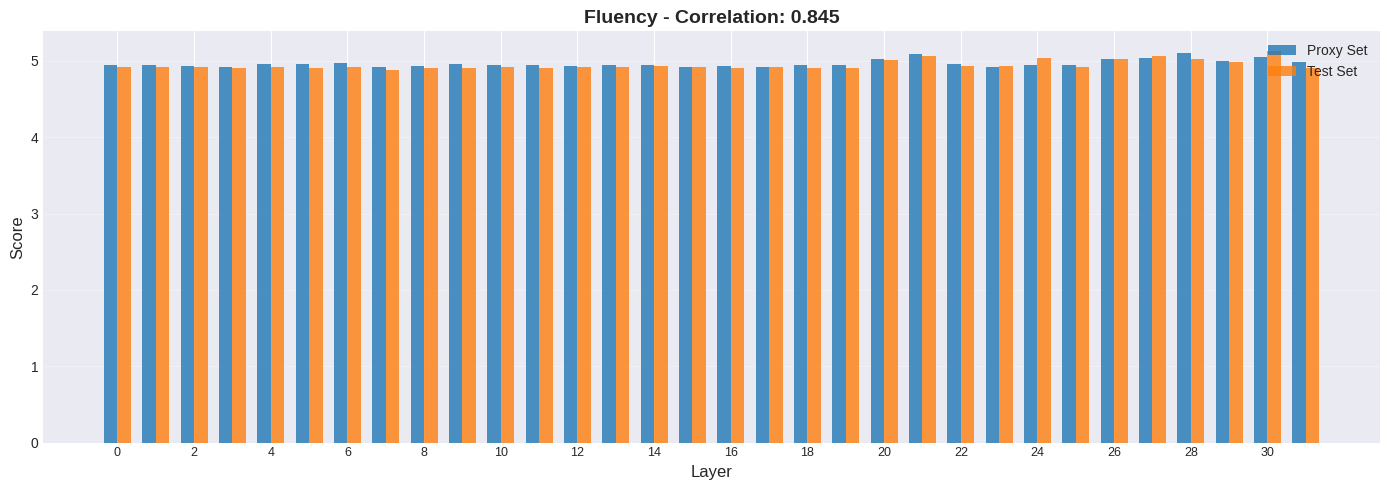

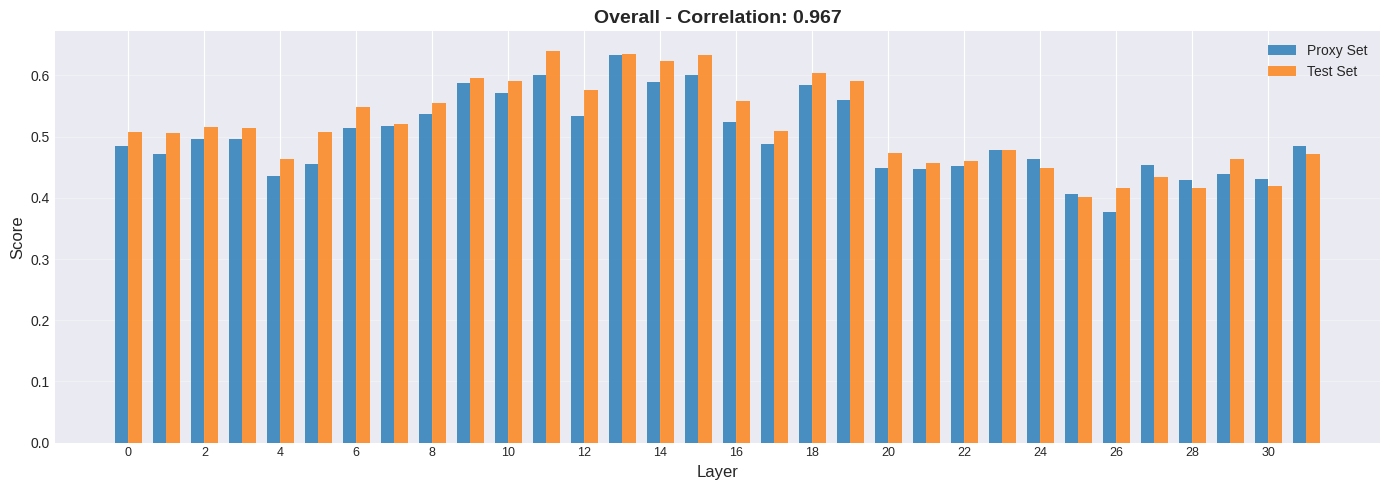

In [10]:
# Bar charts for each metric
for metric_key, info in analysis.items():
    fig, ax = plt.subplots(figsize=(14, 5))
    
    proxy_values = analyzer.proxy_means[metric_key].numpy()
    test_values = analyzer.test_means[metric_key].numpy()
    
    x = np.arange(analyzer.n_layers)
    width = 0.35
    
    ax.bar(x - width/2, proxy_values, width, label='Proxy Set', alpha=0.8)
    ax.bar(x + width/2, test_values, width, label='Test Set', alpha=0.8)
    
    ax.set_xlabel('Layer', fontsize=12)
    ax.set_ylabel('Score', fontsize=12)
    ax.set_title(f"{info['name']} - Correlation: {info['correlation']:.3f}",
                fontsize=14, fontweight='bold')
    ax.legend(loc='best', fontsize=10)
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_xticks(range(0, analyzer.n_layers, 2))
    ax.set_xticklabels(range(0, analyzer.n_layers, 2), fontsize=9)
    
    plt.tight_layout()
    plt.show()

## 8. Summary Table

In [11]:
# Create summary DataFrame
summary_data = []

for metric_key, info in analysis.items():
    summary_data.append({
        'Metric': info['name'],
        'Correlation': f"{info['correlation']:.4f}",
        'Proxy Best Layers': str(info['proxy_best_layers']),
        'Proxy Best Score': f"{info['proxy_score']:.4f}",
        'Test Best Layers': str(info['test_best_layers']),
        'Test Best Score': f"{info['test_score']:.4f}",
        'Overlap': str(info['overlap']) if info['overlap'] else 'None'
    })

df_summary = pd.DataFrame(summary_data)
print("\n" + "="*70)
print("SUMMARY TABLE")
print("="*70)
print(df_summary.to_string(index=False))

# Save to CSV
df_summary.to_csv('wikibio_golden_layer_summary.csv', index=False)
print("\nSummary saved to: wikibio_golden_layer_summary.csv")


SUMMARY TABLE
          Metric Correlation Proxy Best Layers Proxy Best Score Test Best Layers Test Best Score Overlap
Rewrite Accuracy      0.9727              [13]           0.8589             [13]          0.8508    [13]
        Locality      0.9022               [0]           0.8293             [15]          0.8404    None
     Portability         nan                []              nan               []             nan    None
         Fluency      0.8450              [15]           4.9157              [7]          4.8818    None
         Overall      0.9667              [13]           0.6339             [11]          0.6401    None

Summary saved to: wikibio_golden_layer_summary.csv


## 9. Detailed Layer Analysis

Examine layers around the golden layer.

In [15]:
# Create enhanced summary table with metrics as columns - ALL 4 metrics
metric_keys, metric_names = zip(*analyzer.metrics_info)

metric_keys = list(metric_keys)
metric_names = list(metric_names)



print(analysis["overall"]['proxy_best_layers'])
table_data = {
    'Metric': metric_names,
    'Correlation': [f"{analysis[key]['correlation']:.4f}" if key in analysis else "N/A"
                   for key in metric_keys],
    'Test Score of Best Layer Selected by Proxy': [f"{analyzer.test_means[key][analysis['overall']['proxy_best_layers'][0]].item():.4f}" if key in analyzer.test_means else "N/A"
                     for key in metric_keys],
    'Layer 17 Test': [f"{analyzer.test_means[key][0].item():.4f}" if key in analyzer.test_means else "N/A"
                     for key in metric_keys],
    'Test Score Best layer Selected by Test': [f"{analyzer.test_means[key][analysis['overall']['test_best_layers'][0]].item():.4f}" if key in analyzer.test_means else "N/A"
                     for key in metric_keys],
    'Test Best Layers': [str(analysis[key]['test_best_layers']) if key in analysis else "N/A"
                        for key in metric_keys],
    'Proxy Best Layers': [str(analysis[key]['proxy_best_layers']) if key in analysis else "N/A"
                         for key in metric_keys],
    'Proxy Best Score': [f"{analysis[key]['proxy_score']:.4f}" if key in analysis else "N/A"
                        for key in metric_keys],
    'Test Best Score': [f"{analysis[key]['test_score']:.4f}" if key in analysis else "N/A"
                       for key in metric_keys],
    'Layer 17 Proxy': [f"{analyzer.proxy_means[key][17].item():.4f}" if key in analyzer.proxy_means else "N/A"
                      for key in metric_keys],
    'Layer 19 Test': [f"{analyzer.test_means[key][3].item():.4f}" if key in analyzer.test_means else "N/A"
                     for key in metric_keys],
}

# Add rows for performance at layers selected by each metric (for proxy set)
for selector_key in metric_names:
    if selector_key in analysis:
        best_layers = analysis[selector_key]['proxy_best_layers']
        if best_layers:
            # Take first layer if there are ties
            layer = best_layers[0]
            selector_name = analysis[selector_key]['name']
            row_name = f'{selector_name} Best Layer Proxy'
            table_data[row_name] = [f"{analyzer.proxy_means[metric_key][layer].item():.4f}"
                                   if metric_key in analyzer.proxy_means else "N/A"
                                   for metric_key in metric_keys]

# Add rows for performance at layers selected by each metric (for test set)
for selector_key in metric_names:
    if selector_key in analysis:
        best_layers = analysis[selector_key]['test_best_layers']
        if best_layers:
            # Take first layer if there are ties
            layer = best_layers[0]
            selector_name = analysis[selector_key]['name']
            row_name = f'{selector_name} Best Layer Test'
            table_data[row_name] = [f"{analyzer.test_means[metric_key][layer].item():.4f}"
                                   if metric_key in analyzer.test_means else "N/A"
                                   for metric_key in metric_keys]

df_summary = pd.DataFrame(table_data)
df_transposed = df_summary.set_index('Metric').T

print(f"\n{'='*70}")
print("SUMMARY TABLE (with all 4 metrics)")
print(f"{'='*70}\n")
print(df_transposed.to_string())
print()

# Save to CSV
df_transposed.to_csv('wikibio_golden_layer_summary.csv')
print("Summary saved to: wikibio_golden_layer_summary.csv")

[13]

SUMMARY TABLE (with all 4 metrics)

Metric                                     Rewrite Accuracy Locality Portability Fluency Overall
Correlation                                          0.9727   0.9022         nan  0.8450  0.9667
Test Score of Best Layer Selected by Proxy           0.8508   0.8036         nan  4.9165  0.6349
Layer 17 Test                                        0.7049   0.8128         nan  4.9197  0.5076
Test Score Best layer Selected by Test               0.8417   0.8250         nan  4.9025  0.6401
Test Best Layers                                       [13]     [15]          []     [7]    [11]
Proxy Best Layers                                      [13]      [0]          []    [15]    [13]
Proxy Best Score                                     0.8589   0.8293         nan  4.9157  0.6339
Test Best Score                                      0.8508   0.8404         nan  4.8818  0.6401
Layer 17 Proxy                                       0.7429   0.7194         nan  4.9

In [13]:
metric_names = [name for _, name in analyzer.metrics_info]
metric_keys = [key for key, _ in analyzer.metrics_info]

for key in metric_keys:
    print(key)

# for key in metric_keys:
key = "post_rewrite_acc"
for layer in [17,19,15,12,16,18]:
    print(f"{analyzer.test_means[key][layer].item():.4f}")
    # print(f"key-{key} layer-{layer}: {analyzer.test_means[key][layer].item():.4f}")

min = analyzer.test_means[key][0].item()
for layer in range(32):
    if min>analyzer.test_means[key][layer].item():
        min = analyzer.test_means[key][layer].item()
print(f"min: {min:.4f}")

post_rewrite_acc
post_locality_acc
post_portability_acc
post_fluency
overall
0.7664
0.8448
0.8258
0.8098
0.7788
0.8441
min: 0.6806


In [14]:
metric_names = [name for _, name in metrics_info]
metric_keys = [key for key, _ in metrics_info]

for key in metric_keys:
    print(key)

# for key in metric_keys:
key = "post_portability_acc"
for layer in [19,23,29,15,25]:
    print(f"{analyzer.test_means[key][layer].item():.4f}")
    # print(f"key-{key} layer-{layer}: {analyzer.test_means[key][layer].item():.4f}")

min = analyzer.test_means[key][0].item()
for layer in range(48):
    if min>analyzer.test_means[key][layer].item():
        min = analyzer.test_means[key][layer].item()
print(f"min: {min:.4f}")

post_rewrite_acc
post_locality_acc
post_portability_acc
post_fluency
overall
nan
nan
nan
nan
nan


IndexError: index 32 is out of bounds for dimension 0 with size 32

In [ ]:
metric_names = [name for _, name in analyzer.metrics_info]
metric_keys = [key for key, _ in analyzer.metrics_info]

for key in metric_keys:
    print(key)

# for key in metric_keys:
key = "post_fluency"
for layer in [43, 0]:
    print(f"{analyzer.test_means[key][layer].item():.4f}")
    # print(f"key-{key} layer-{layer}: {analyzer.test_means[key][layer].item():.4f}")

min = analyzer.test_means[key][0].item()
for layer in range(32):
    if min<analyzer.test_means[key][layer].item():
        min = analyzer.test_means[key][layer].item()
print(f"min: {min:.4f}")

post_rewrite_acc
post_locality_acc
post_portability_acc
post_fluency
overall
5.4128
5.1416
min: 6.1059


## Notes

### WikiBio-Specific Handling:
1. **Nested JSON structure**: Extracts from `post.rewrite_acc[0]`, `post.locality.Relation_Specificity_acc` (averaged), `post.fluency.ngram_entropy`
2. **Fluency negation**: Lower fluency is better, so we negate before normalization
3. **Three metrics only**: rewrite_acc, locality_acc, fluency (no portability for WikiBio)
4. **Overall**: Average of three normalized metrics

### Interpretation:
- **Golden Layer**: Layer(s) that perform best on both proxy and test sets
- **High Correlation**: Indicates proxy set is representative of test set
- **Overlap**: Agreement between proxy and test best layers

## 10. Proxy Size Stability Analysis

Analyze how the selected golden layer changes with different proxy sizes.

In [ ]:
from collections import Counter

# Test different proxy sizes to see stability
proxy_sizes = list(range(1, min(analyzer.n_samples, 501)))

proxy_best_layers_scalar = []
test_best_layers_scalar = []

print("Analyzing proxy size stability...")
print(f"Testing proxy sizes from 1 to {len(proxy_sizes)}")

for i, proxy_size in enumerate(proxy_sizes):
    if (i + 1) % 50 == 0:
        print(f"  Progress: {i+1}/{len(proxy_sizes)} proxy sizes tested")
    
    # Split dataset with current proxy size
    torch.manual_seed(42)
    indices = torch.randperm(analyzer.n_samples)
    
    temp_proxy_indices = indices[:proxy_size]
    temp_test_indices = indices[proxy_size:]
    
    # Skip if test set is too small
    if len(temp_test_indices) < 10:
        continue
    
    # Compute means for overall metric
    proxy_overall = analyzer.results['overall'][temp_proxy_indices].nanmean(dim=0)
    test_overall = analyzer.results['overall'][temp_test_indices].nanmean(dim=0)
    
    # Find best layers
    valid_proxy = ~torch.isnan(proxy_overall)
    valid_test = ~torch.isnan(test_overall)
    
    if valid_proxy.sum() > 0:
        proxy_max = proxy_overall[valid_proxy].max()
        proxy_layers = torch.where(proxy_overall == proxy_max)[0].tolist()
    else:
        proxy_layers = []
    
    if valid_test.sum() > 0:
        test_max = test_overall[valid_test].max()
        test_layers = torch.where(test_overall == test_max)[0].tolist()
    else:
        test_layers = []
    
    # Reduce list to scalar using MODE (most common layer)
    if proxy_layers:
        proxy_mode = Counter(proxy_layers).most_common(1)[0][0]
    else:
        proxy_mode = np.nan
    
    if test_layers:
        test_mode = Counter(test_layers).most_common(1)[0][0]
    else:
        test_mode = np.nan
    
    proxy_best_layers_scalar.append(proxy_mode)
    test_best_layers_scalar.append(test_mode)

print(f"\nCompleted: {len(proxy_best_layers_scalar)} data points collected")

TypeError: 'float' object is not callable

## 9a. Proxy Size Comparison (Quick Test)

Compare golden layer identification with different proxy sizes.

In [ ]:
# Compare results with different proxy sizes
test_proxy_sizes = [50, 100, 200]

print(f"\n{'='*70}")
print("PROXY SIZE COMPARISON")
print(f"{'='*70}")

for test_size in test_proxy_sizes:
    if test_size >= analyzer.n_samples:
        print(f"\nProxy size: {test_size} - Skipped (not enough samples)")
        continue
        
    # Split with current proxy size
    torch.manual_seed(42)
    indices = torch.randperm(analyzer.n_samples)
    
    temp_proxy_indices = indices[:test_size]
    temp_test_indices = indices[test_size:]
    
    # Compute means
    temp_proxy_overall = analyzer.results['overall'][temp_proxy_indices].nanmean(dim=0)
    temp_test_overall = analyzer.results['overall'][temp_test_indices].nanmean(dim=0)
    
    # Find best layers
    valid_proxy = ~torch.isnan(temp_proxy_overall)
    valid_test = ~torch.isnan(temp_test_overall)
    
    if valid_proxy.sum() > 0:
        proxy_max = temp_proxy_overall[valid_proxy].max()
        proxy_best = torch.where(temp_proxy_overall == proxy_max)[0].tolist()
    else:
        proxy_best = []
    
    if valid_test.sum() > 0:
        test_max = temp_test_overall[valid_test].max()
        test_best = torch.where(temp_test_overall == test_max)[0].tolist()
    else:
        test_best = []
    
    overlap = list(set(proxy_best) & set(test_best))
    
    # Compute correlation
    valid_mask = ~(torch.isnan(temp_proxy_overall) | torch.isnan(temp_test_overall))
    if valid_mask.sum() > 1:
        corr = torch.corrcoef(torch.stack([
            temp_proxy_overall[valid_mask],
            temp_test_overall[valid_mask]
        ]))[0, 1].item()
    else:
        corr = np.nan
    
    print(f"\nProxy size: {test_size}")
    print(f"  Proxy best layers: {proxy_best}")
    print(f"  Test best layers:  {test_best}")
    print(f"  Overlap: {overlap if overlap else 'None'}")
    print(f"  Correlation: {corr:.4f}")


PROXY SIZE COMPARISON

Proxy size: 50
  Proxy best layers: [16]
  Test best layers:  [19]
  Overlap: None
  Correlation: 0.9624

Proxy size: 100
  Proxy best layers: [20]
  Test best layers:  [19]
  Overlap: None
  Correlation: 0.9861

Proxy size: 200
  Proxy best layers: [21]
  Test best layers:  [19]
  Overlap: None
  Correlation: 0.9861


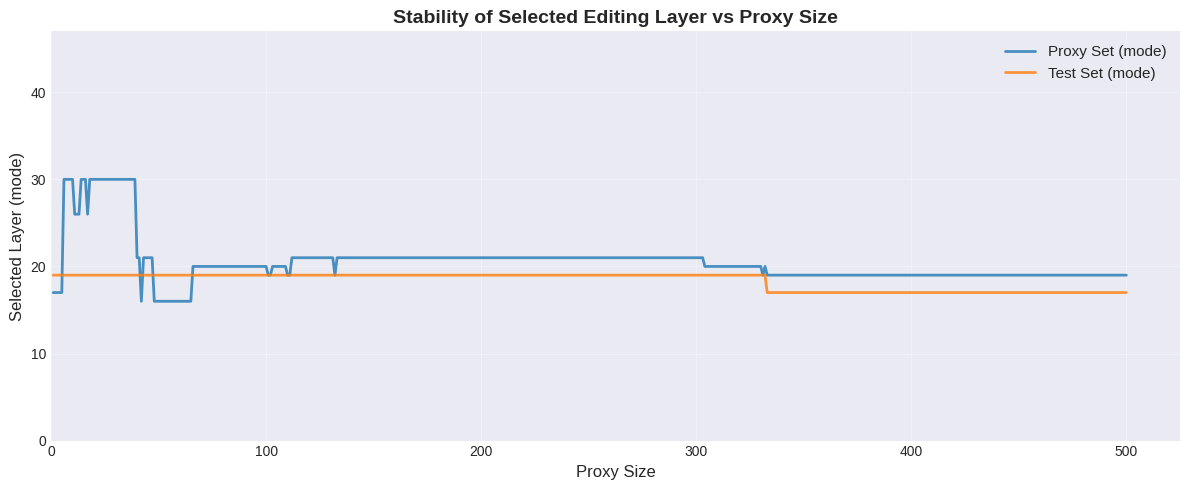


Stability Statistics:
Proxy set:
  Most common layer: 21
  Std deviation: 2.73
  Range: [16, 30]

Test set:
  Most common layer: 19
  Std deviation: 0.94
  Range: [17, 19]


In [ ]:
# Plot stability of selected layer vs proxy size
plt.figure(figsize=(12, 5))
plt.plot(proxy_sizes[:len(proxy_best_layers_scalar)], 
         proxy_best_layers_scalar, 
         label='Proxy Set (mode)', 
         linewidth=2, 
         alpha=0.8)
plt.plot(proxy_sizes[:len(test_best_layers_scalar)], 
         test_best_layers_scalar, 
         label='Test Set (mode)', 
         linewidth=2, 
         alpha=0.8)

plt.xlabel("Proxy Size", fontsize=12)
plt.ylabel("Selected Layer (mode)", fontsize=12)
plt.title("Stability of Selected Editing Layer vs Proxy Size", fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.xlim(left=0)
plt.ylim(0, analyzer.n_layers - 1)
plt.tight_layout()
plt.show()

# Calculate stability statistics
proxy_layers_array = np.array(proxy_best_layers_scalar)
test_layers_array = np.array(test_best_layers_scalar)

# Remove NaN values for statistics
proxy_valid = proxy_layers_array[~np.isnan(proxy_layers_array)]
test_valid = test_layers_array[~np.isnan(test_layers_array)]

print("\nStability Statistics:")
print("="*70)
print(f"Proxy set:")
print(f"  Most common layer: {Counter(proxy_valid.astype(int)).most_common(1)[0][0] if len(proxy_valid) > 0 else 'N/A'}")
print(f"  Std deviation: {proxy_valid.std():.2f}")
print(f"  Range: [{proxy_valid.min():.0f}, {proxy_valid.max():.0f}]")
print(f"\nTest set:")
print(f"  Most common layer: {Counter(test_valid.astype(int)).most_common(1)[0][0] if len(test_valid) > 0 else 'N/A'}")
print(f"  Std deviation: {test_valid.std():.2f}")
print(f"  Range: [{test_valid.min():.0f}, {test_valid.max():.0f}]")

## 11. Agreement Analysis

Analyze which metrics have matching best layers between proxy and test sets.

In [ ]:
print(f"\n{'='*70}")
print("AGREEMENT ANALYSIS")
print(f"{'='*70}")

for metric_key in metric_names:
    if metric_key in analysis:
        info = analysis[metric_key]
        overlap = info['overlap']
        proxy_layers = info['proxy_best_layers']
        test_layers = info['test_best_layers']
        metric_name = info['name']
        
        if overlap:
            print(f"\n{metric_name}:")
            print(f"  ✓ MATCH! Common best layers: {overlap}")
        else:
            print(f"\n{metric_name}:")
            print(f"  ✗ NO MATCH")
            print(f"    Proxy: {proxy_layers}")
            print(f"    Test:  {test_layers}")


AGREEMENT ANALYSIS


## 12. Proxy-Test Agreement Plot

Visualize agreement between proxy and test set layer selections across different proxy sizes.

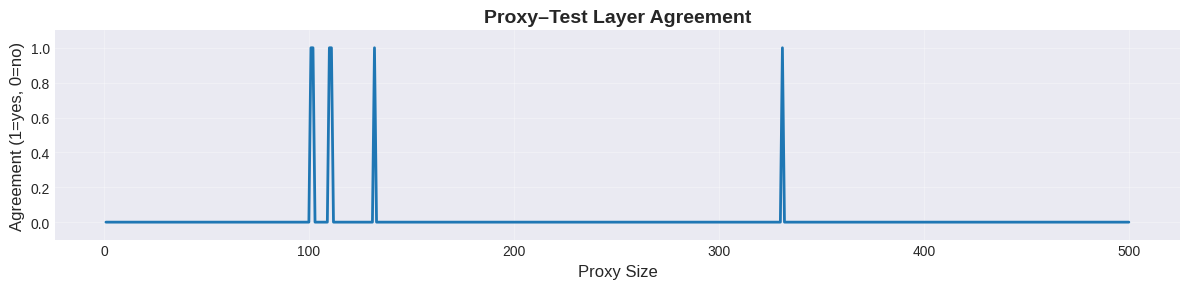


Agreement Statistics:
  Overall agreement rate: 1.20%
  Agreement count: 6 / 500
  First agreement at proxy size: 101


In [ ]:
# Plot agreement between proxy and test selections
agreement = np.array(proxy_best_layers_scalar) == np.array(test_best_layers_scalar)

plt.figure(figsize=(12, 3))
plt.plot(proxy_sizes[:len(agreement)], agreement.astype(int), linewidth=2)
plt.xlabel("Proxy Size", fontsize=12)
plt.ylabel("Agreement (1=yes, 0=no)", fontsize=12)
plt.title("Proxy–Test Layer Agreement", fontsize=14, fontweight='bold')
plt.ylim(-0.1, 1.1)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Calculate agreement statistics
agreement_rate = agreement.mean()
print(f"\nAgreement Statistics:")
print(f"  Overall agreement rate: {agreement_rate:.2%}")
print(f"  Agreement count: {agreement.sum()} / {len(agreement)}")
print(f"  First agreement at proxy size: {proxy_sizes[np.where(agreement)[0][0]] if agreement.any() else 'None'}")

## 13. Save Results

Save all analysis results and figures for future reference.

In [ ]:
# Create output directories
import os
os.makedirs('./figures', exist_ok=True)
os.makedirs('./results', exist_ok=True)

# Save bar charts for ALL 4 metrics
for metric_key in metric_names:
    if metric_key in analyzer.proxy_means:
        fig, ax = plt.subplots(figsize=(14, 5))
        
        proxy_values = analyzer.proxy_means[metric_key].numpy()
        test_values = analyzer.test_means[metric_key].numpy()
        
        x = np.arange(analyzer.n_layers)
        width = 0.35
        
        ax.bar(x - width/2, proxy_values, width, label='Proxy Set', alpha=0.8)
        ax.bar(x + width/2, test_values, width, label='Test Set', alpha=0.8)
        
        ax.set_xlabel('Layer', fontsize=12)
        ax.set_ylabel('Score', fontsize=12)
        
        metric_name = analysis[metric_key]['name'] if metric_key in analysis else metric_key
        correlation = analysis[metric_key]['correlation'] if metric_key in analysis else 0
        
        # Add note for fluency
        title_suffix = " (lower is better)" if metric_key == 'fluency' else ""
        ax.set_title(f'{metric_name}{title_suffix} - Correlation: {correlation:.3f}',
                    fontsize=14, fontweight='bold')
        ax.legend(loc='best', fontsize=10)
        ax.grid(True, alpha=0.3, axis='y')
        ax.set_xticks(range(0, analyzer.n_layers, 2))
        ax.set_xticklabels(range(0, analyzer.n_layers, 2), fontsize=9)
        
        plt.tight_layout()
        plt.savefig(f'./figures/{metric_key}_comparison.png', dpi=150, bbox_inches='tight')
        plt.close()
        print(f"Saved: figures/{metric_key}_comparison.png")

# Save all results as torch tensors
results_to_save = {
    'results': analyzer.results,
    'proxy_means': analyzer.proxy_means,
    'test_means': analyzer.test_means,
    'analysis': analysis,
    'proxy_indices': analyzer.proxy_indices,
    'test_indices': analyzer.test_indices,
    'n_samples': analyzer.n_samples,
    'n_layers': analyzer.n_layers,
    'proxy_best_layers_scalar': proxy_best_layers_scalar,
    'test_best_layers_scalar': test_best_layers_scalar,
    'proxy_sizes': proxy_sizes
}

torch.save(results_to_save, './results/wikirecent_golden_layer_analysis.pt')
print("Saved: results/wikibio_golden_layer_analysis.pt")

# Save detailed CSV with ALL 4 layer performances
detailed_data = []
for layer in range(analyzer.n_layers):
    row = {'Layer': layer}
    for metric_key in metric_names:
        if metric_key in analyzer.proxy_means:
            row[f'{metric_key}_proxy'] = analyzer.proxy_means[metric_key][layer].item()
            row[f'{metric_key}_test'] = analyzer.test_means[metric_key][layer].item()
    detailed_data.append(row)

df_detailed = pd.DataFrame(detailed_data)
df_detailed.to_csv('./results/wikirecent_layer_performance_detailed.csv', index=False)
print("Saved: results/wikirecent_layer_performance_detailed.csv")

print("\nAll results saved successfully!")

Saved: results/wikibio_golden_layer_analysis.pt
Saved: results/wikirecent_layer_performance_detailed.csv

All results saved successfully!
